# 🧩 04 — EDA Multivariado y Construcción del Índice Compuesto
**Objetivos:**
1. Sintetizar las dimensiones de fecundidad, longevidad, estructura etaria, equidad y migración mediante **Análisis de Componentes Principales (PCA)**.
2. Construir formalmente el **Índice de Transición Demográfica (DTI)** y justificar sus propiedades matemáticas y éticas.
3. Identificar **regímenes demográficos globales** mediante clustering no supervisado (K-Means).
4. Contrastar la hipótesis clásica de transición evaluando formalmente la **$\sigma$-convergencia** temporal (1950–2023).
5. Generar los datasets analíticos de la capa **Gold** (`data/gold/`).

**Input:** `data/silver/wpp2024_countries_estimates.parquet`  
**Outputs:** 
- Datasets en `data/gold/`: `demographic_profiles.parquet`, `convergence_metrics.parquet`, `cluster_profiles.parquet`
- Figuras en `outputs/figures/eda/`: `04_pca_variance_loadings.png`, `04_pca_biplot.png`, `04_cluster_regimes.png`, `04_sigma_convergence.png`, `04_country_trajectories.png`

---

## 4.1 Imports, configuración y carga de datos Silver
Importamos las librerías estadísticas clave y cargamos las estimaciones de países (`LocTypeID == 4`, 1950–2023).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuración de rutas del proyecto
sys.path.insert(0, str(Path.cwd().parent))
from src.config import SILVER, GOLD, FIGURES_EDA, SEED
from src.viz import setup_style, save_figure

setup_style()

# Cargar estimaciones Silver
df = pd.read_parquet(SILVER / 'wpp2024_countries_estimates.parquet')

# Mapeo oficial de regiones UN M49 (ParentID a Continente)
region_map = {
    910: 'Africa', 911: 'Africa', 912: 'Africa', 913: 'Africa', 914: 'Africa',
    5500: 'Asia', 906: 'Asia', 5501: 'Asia', 920: 'Asia', 922: 'Asia',
    923: 'Europe', 924: 'Europe', 925: 'Europe', 926: 'Europe',
    915: 'Latin America & Caribbean', 916: 'Latin America & Caribbean', 931: 'Latin America & Caribbean',
    918: 'Northern America',
    927: 'Oceania', 928: 'Oceania', 954: 'Oceania', 957: 'Oceania'
}
df['Continent'] = df['ParentID'].map(region_map)

# Definir los 7 indicadores seleccionados del embudo metodológico (Notebooks 02 y 03)
feature_cols = ['LEx', 'IMR', 'TFR', 'MedianAgePop', 'PopGrowthRate', 'GenderGapLE', 'CNMR']

# Verificar integridad
df_analysis = df.dropna(subset=feature_cols).copy()
print(f"Dimensiones de trabajo: {df_analysis.shape[0]:,} observaciones x {len(feature_cols)} indicadores")
print(f"Indicadores de los 4 pilares: {feature_cols}")

Dimensiones de trabajo: 17,538 observaciones x 7 indicadores
Indicadores de los 4 pilares: ['LEx', 'IMR', 'TFR', 'MedianAgePop', 'PopGrowthRate', 'GenderGapLE', 'CNMR']


## 4.2 PCA — Reducción de Dimensionalidad y Construcción del Índice Compuesto
Para construir una métrica objetiva y no arbitraria que responda a la **Pregunta Guía #5**, utilizamos PCA sobre las 7 variables estandarizadas ($Z$-scores).
* **Objetivo:** Determinar cuántas dimensiones latentes resumen la dinámica demográfica global y extraer ponderaciones basadas en la varianza empírica de los datos.
* **Orientación conceptual:** El primer componente ($PC1$) captura el eje de desarrollo y transición. Se invierte de signo para que mayores valores reflejen mayor avance en longevidad y modernización sanitaria.

  💾 Saved: outputs\figures\eda\04_pca_variance_loadings.png


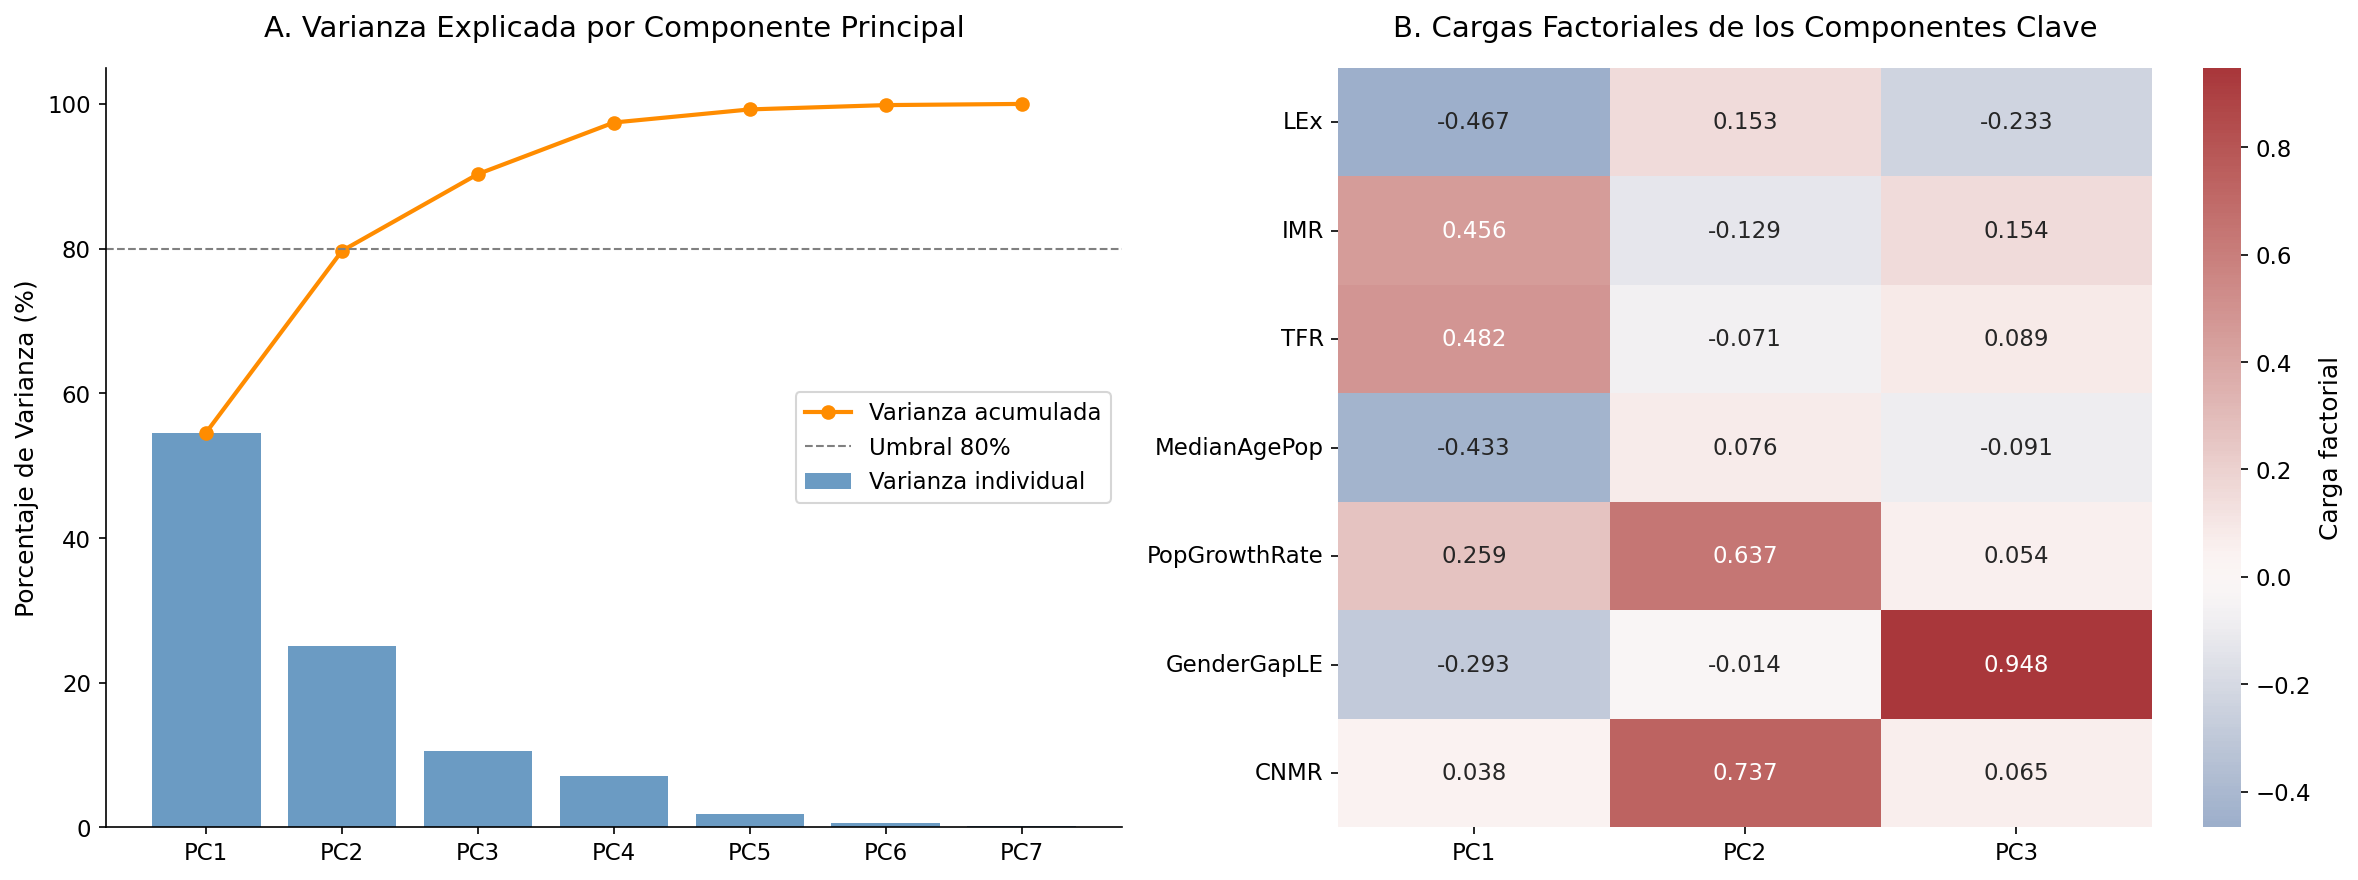

Varianza acumulada PC1 + PC2: 79.70%
Varianza acumulada PC1 + PC2 + PC3: 90.31%


In [2]:
# 1. Estandarización de variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_analysis[feature_cols])

# 2. Ajuste de PCA
pca = PCA(n_components=len(feature_cols), random_state=SEED)
X_pca = pca.fit_transform(X_scaled)

# 3. Varianza explicada
var_exp = pca.explained_variance_ratio_ * 100
var_cum = np.cumsum(var_exp)

# Visualización: Scree plot y Loadings
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Scree plot
axes[0].bar([f"PC{i+1}" for i in range(len(var_exp))], var_exp, color='steelblue', alpha=0.8, label='Varianza individual')
axes[0].plot([f"PC{i+1}" for i in range(len(var_exp))], var_cum, color='darkorange', marker='o', linewidth=2, label='Varianza acumulada')
axes[0].axhline(80, color='gray', linestyle='--', linewidth=1, label='Umbral 80%')
axes[0].set_title("A. Varianza Explicada por Componente Principal", pad=15)
axes[0].set_ylabel("Porcentaje de Varianza (%)")
axes[0].set_ylim(0, 105)
axes[0].legend(loc='center right', frameon=True)

# B. Heatmap de Cargas (Loadings) en PC1, PC2 y PC3
loadings_df = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=[f"PC{i+1}" for i in range(len(feature_cols))]
)
sns.heatmap(loadings_df[['PC1', 'PC2', 'PC3']], annot=True, fmt='.3f', cmap='vlag', center=0, ax=axes[1], cbar_kws={'label': 'Carga factorial'})
axes[1].set_title("B. Cargas Factoriales de los Componentes Clave", pad=15)

plt.tight_layout()
save_figure(fig, "04_pca_variance_loadings")
plt.show()

print(f"Varianza acumulada PC1 + PC2: {var_cum[1]:.2f}%")
print(f"Varianza acumulada PC1 + PC2 + PC3: {var_cum[2]:.2f}%")

### 💡 Interpretación de los Componentes Principales:
1. **$PC1$ (54.58% de varianza) — Eje de Transición Demográfica y Salud:**
   * Cargas negativas altas en `LEx` ($-0.467$) y `MedianAgePop` ($-0.433$).
   * Cargas positivas altas en `TFR` ($+0.482$) e `IMR` ($+0.456$).
   * Refleja exactamente la transición clásica: pasar de alta natalidad/alta mortalidad infantil a alta esperanza de vida y pirámides envejecidas.
   * **Inversión de signo:** Definimos el **Índice de Transición Demográfica (DTI)** invirtiendo $PC1$ ($	ext{DTI}^* = -PC1$), de modo que valores altos indiquen mayor madurez de transición.
2. **$PC2$ (25.12% de varianza) — Eje de Dinámica Migratoria y Crecimiento:**
   * Cargas positivas dominadas por la Tasa Neta de Migración `CNMR` ($+0.737$) y la Tasa de Crecimiento `PopGrowthRate` ($+0.637$).
   * Es ortogonal a la salud básica: separa a los países receptores con dinamismo económico de aquellos en estancamiento o despoblación.
3. **$PC3$ (10.61% de varianza) — Eje de Disparidad de Género:**
   * Dominado casi exclusivamente por `GenderGapLE` ($+0.948$). Captura la sobremortalidad masculina adulta.

  💾 Saved: outputs\figures\eda\04_pca_biplot.png


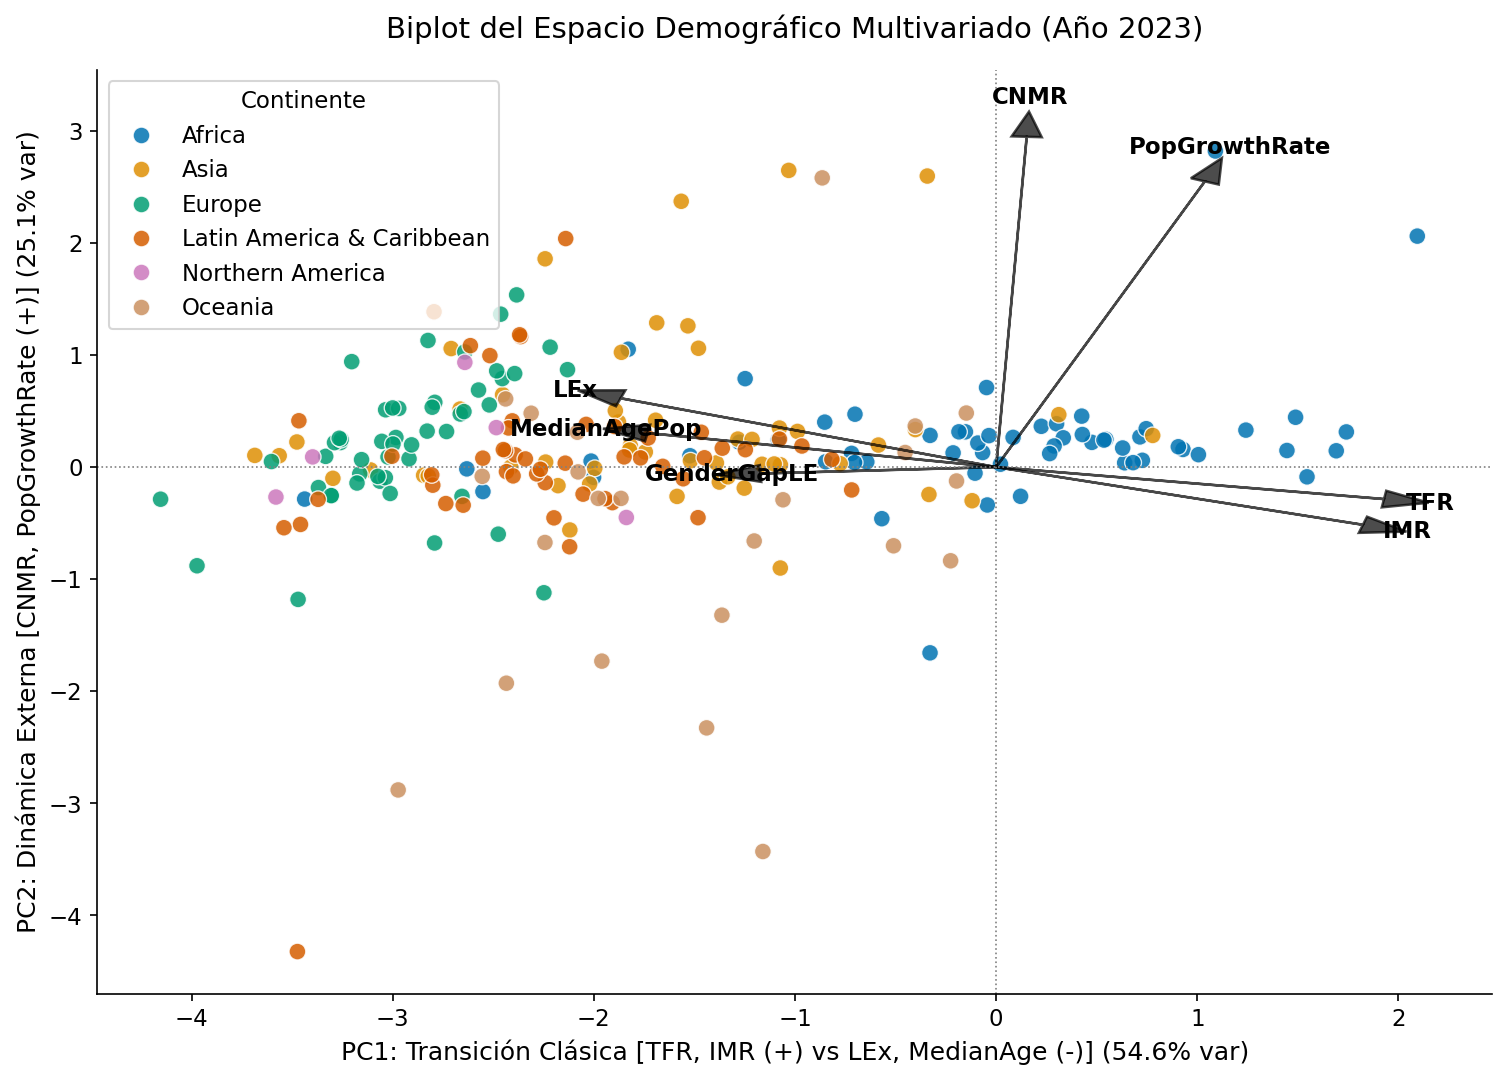

Top 5 Países con Mayor DTI (Transición Avanzada / Envejecimiento) en 2023:


,Location,Continent,DTI,LEx,TFR,MedianAgePop
10359,Holy See,Europe,57.757934,82.9848,1.0000,59.6250
8805,Ukraine,Europe,56.749819,73.4225,0.9770,41.9843
5105,Japan,Asia,55.151445,84.7123,1.2079,48.9585
11617,Monaco,Europe,54.690124,86.3724,2.1099,54.3560
15761,Saint Pierre and Miquelon,Northern America,54.566696,76.7578,1.2670,46.4025



Top 5 Países con Menor DTI (Transición Incipiente / Alta Fecundidad) en 2023:


,Location,Continent,DTI,LEx,TFR,MedianAgePop
1775,Chad,Africa,22.992980,55.0692,6.1203,15.4007
3921,Niger,Africa,24.955147,61.1833,6.0615,15.2495
1701,Central African Republic,Africa,25.234482,57.4077,6.0117,14.3199
3995,Nigeria,Africa,26.043689,54.4623,4.4817,17.7545
1109,Somalia,Africa,26.360558,58.8158,6.1319,15.4468


In [3]:
# Asignar coordenadas PCA al DataFrame
df_analysis['PC1'] = X_pca[:, 0]
df_analysis['PC2'] = X_pca[:, 1]
df_analysis['PC3'] = X_pca[:, 2]

# Construcción formal del DTI (Demographic Transition Index):
# 1. Invertir PC1 para dar sentido positivo de longevidad y control de mortalidad
raw_dti = -df_analysis['PC1']

# 2. Escalamiento Min-Max a rango intuitivo [0, 100]
dti_min, dti_max = raw_dti.min(), raw_dti.max()
df_analysis['DTI'] = ((raw_dti - dti_min) / (dti_max - dti_min)) * 100

# Visualización: Biplot en el año 2023
df_2023 = df_analysis[df_analysis['Time'] == 2023].copy()

fig, ax = plt.subplots(figsize=(12, 8))

# Puntos de países coloreados por continente
sns.scatterplot(
    data=df_2023,
    x='PC1',
    y='PC2',
    hue='Continent',
    palette='colorblind',
    s=65,
    alpha=0.85,
    ax=ax
)

# Vectores de carga de variables
scale_arrow = 4.0
for i, var in enumerate(feature_cols):
    c1 = loadings_df.loc[var, 'PC1'] * scale_arrow
    c2 = loadings_df.loc[var, 'PC2'] * scale_arrow
    ax.arrow(0, 0, c1, c2, color='black', alpha=0.7, head_width=0.15, linewidth=1.2)
    ax.text(c1 * 1.12, c2 * 1.12, var, color='black', fontsize=11, weight='bold', ha='center', va='center')

ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
ax.axvline(0, color='gray', linestyle=':', linewidth=0.8)
ax.set_title("Biplot del Espacio Demográfico Multivariado (Año 2023)", pad=15)
ax.set_xlabel("PC1: Transición Clásica [TFR, IMR (+) vs LEx, MedianAge (-)] (54.6% var)")
ax.set_ylabel("PC2: Dinámica Externa [CNMR, PopGrowthRate (+)] (25.1% var)")
ax.legend(title="Continente", loc="upper left", frameon=True)

save_figure(fig, "04_pca_biplot")
plt.show()

# Resumen de países extremos en el DTI en 2023
print("Top 5 Países con Mayor DTI (Transición Avanzada / Envejecimiento) en 2023:")
display(df_2023[['Location', 'Continent', 'DTI', 'LEx', 'TFR', 'MedianAgePop']].sort_values(by='DTI', ascending=False).head(5))

print("")
print("Top 5 Países con Menor DTI (Transición Incipiente / Alta Fecundidad) en 2023:")
display(df_2023[['Location', 'Continent', 'DTI', 'LEx', 'TFR', 'MedianAgePop']].sort_values(by='DTI', ascending=True).head(5))

## 4.3 Clustering de Regímenes Demográficos (K-Means)
Para clasificar los países en perfiles no lineales de comportamiento, evaluamos el agrupamiento en base a los 7 indicadores estandarizados en el año más reciente (2023).
* Evaluamos la inercia (método del codo) y el coeficiente de silueta para $K \in [2, 6]$.
* Caracterizamos demográficamente cada clúster para responder a la **Pregunta Guía #6 de la ASA** (*¿Se agrupan los países en perfiles distintivos según cómo han evolucionado conjuntamente sus indicadores?*).

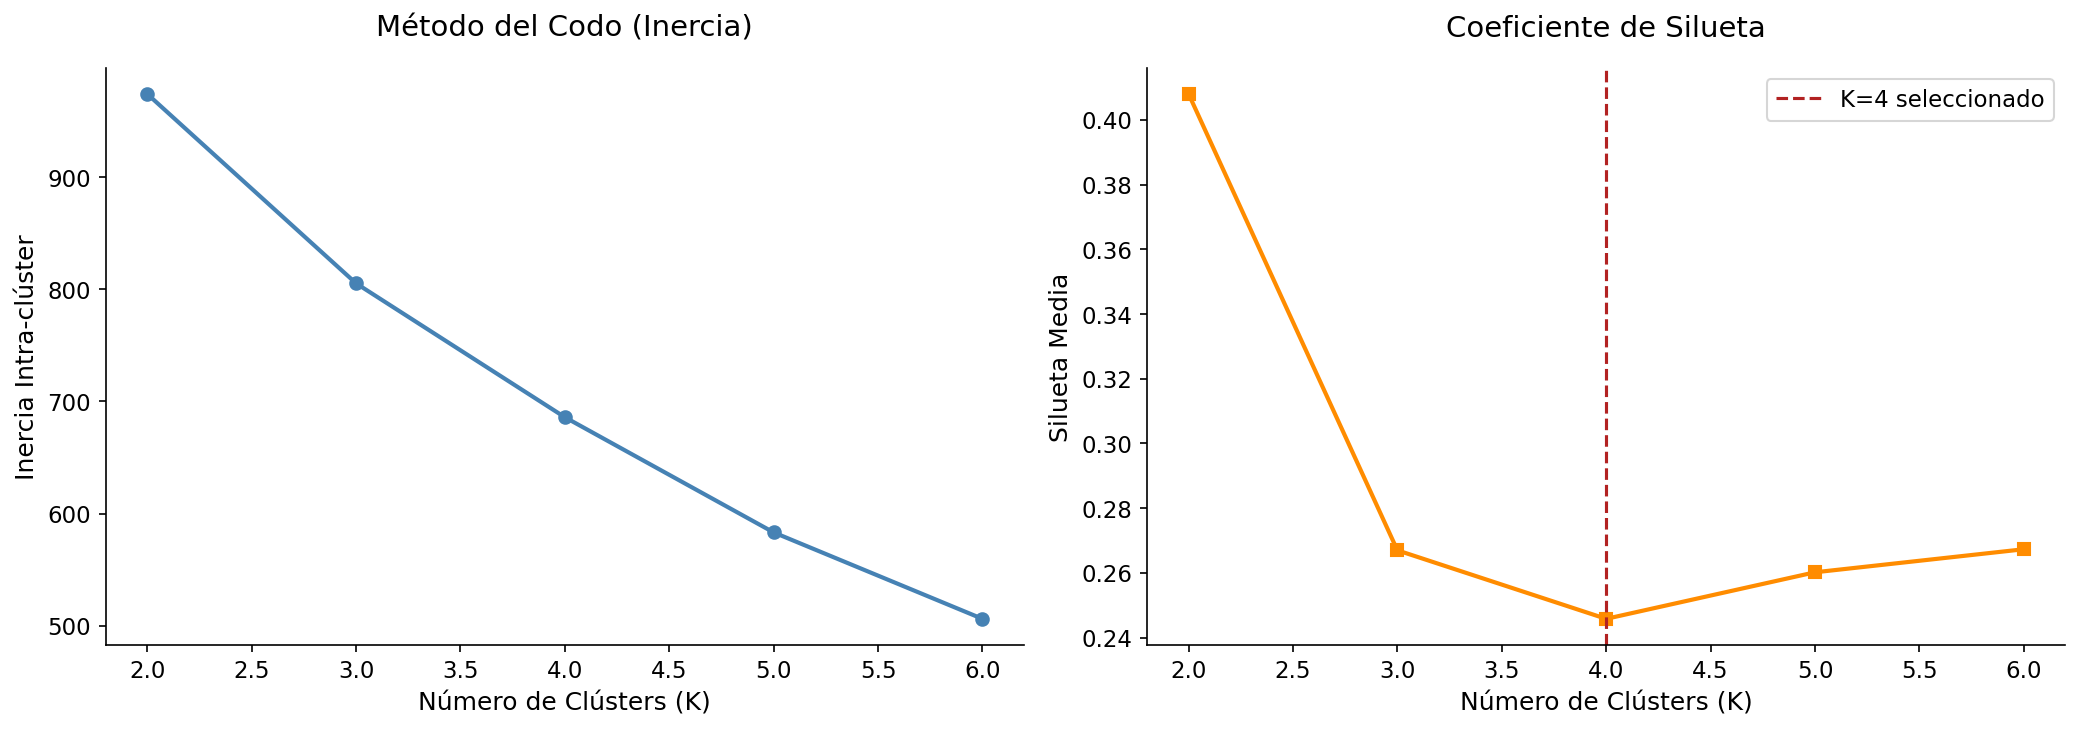

  💾 Saved: outputs\figures\eda\04_cluster_regimes.png


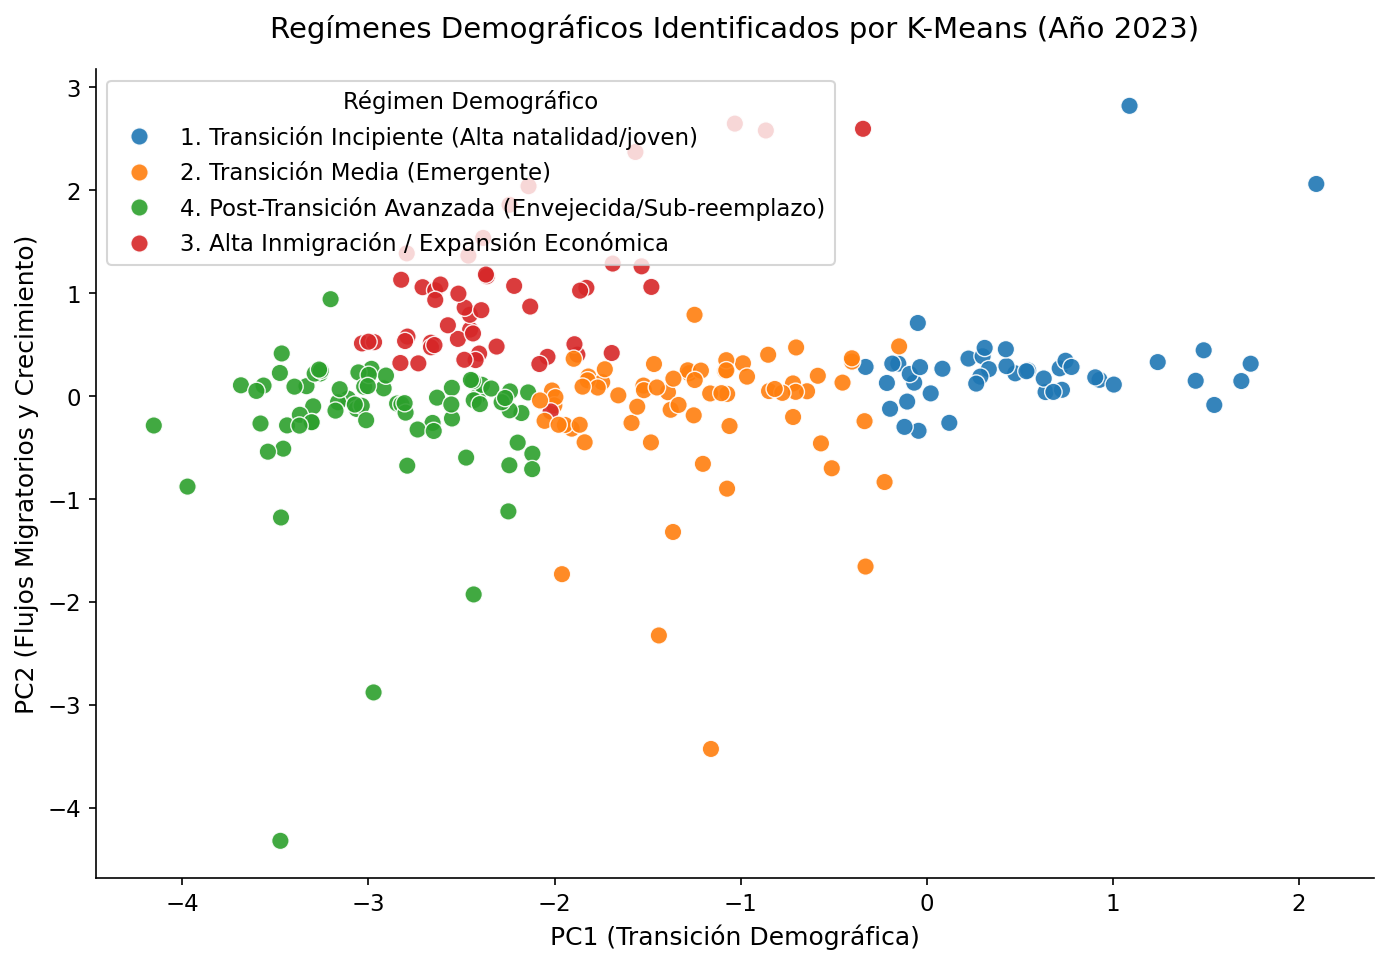

Perfil Promedio de los 4 Regímenes Demográficos:


LEx         TFR        \
                                                     mean count  mean count   
Regime                                                                        
1. Transición Incipiente (Alta natalidad/joven)     64.01    44  4.33    44   
2. Transición Media (Emergente)                     71.44    69  2.53    69   
3. Alta Inmigración / Expansión Económica           80.62    51  1.59    51   
4. Post-Transición Avanzada (Envejecida/Sub-ree...  78.30    73  1.50    73   

                                                      IMR       MedianAgePop  \
                                                     mean count         mean   
Regime                                                                         
1. Transición Incipiente (Alta natalidad/joven)     44.19    44        18.07   
2. Transición Media (Emergente)                     18.64    69        26.18   
3. Alta Inmigración / Expansión Económica            5.48    51        36.99   
4. Post-Transición Avanzada (Envejecida/Sub-ree...   6.77    73        40.75   

                                                         PopGrowthRate        \
                                                   count          mean count   
Regime                                                                         
1. Transición Incipiente (Alta natalidad/joven)       44          2.63    44   
2. Transición Media (Emergente)                       69          0.93    69   
3. Alta Inmigración / Expansión Económica             51          1.49    51   
4. Post-Transición Avanzada (Envejecida/Sub-ree...    73         -0.39    73   

                                                     CNMR          DTI        
                                                     mean count   mean count  
Regime                                                                        
1. Transición Incipiente (Alta natalidad/joven)      0.67    44  31.75    44  
2. Transición Media (Emergente)                     -3.87    69  41.58    69  
3. Alta Inmigración / Expansión Económica           10.73    51  47.29    51  
4. Post-Transición Avanzada (Envejecida/Sub-ree...  -2.88    73  50.93    73

In [4]:
# Diagnóstico de número de clústers K en 2023
X_2023 = df_2023[feature_cols]
X_2023_scaled = StandardScaler().fit_transform(X_2023)

k_range = range(2, 7)
inertias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=15).fit(X_2023_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_2023_scaled, km.labels_))

# Visualización del Codo y Silueta
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue', linewidth=2)
axes[0].set_title("Método del Codo (Inercia)", pad=15)
axes[0].set_xlabel("Número de Clústers (K)")
axes[0].set_ylabel("Inercia Intra-clúster")

axes[1].plot(k_range, silhouettes, marker='s', color='darkorange', linewidth=2)
axes[1].axvline(4, color='firebrick', linestyle='--', label='K=4 seleccionado')
axes[1].set_title("Coeficiente de Silueta", pad=15)
axes[1].set_xlabel("Número de Clústers (K)")
axes[1].set_ylabel("Silueta Media")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

# Ajuste definitivo con K=4 regímenes
kmeans_final = KMeans(n_clusters=4, random_state=SEED, n_init=20)
df_2023['Cluster'] = kmeans_final.fit_predict(X_2023_scaled)

# Asignar nombres conceptuales según medias de LEx y TFR
cluster_means = df_2023.groupby('Cluster')[feature_cols].mean()

# Ordenar clusters por DTI promedio
cluster_order = df_2023.groupby('Cluster')['DTI'].mean().sort_values().index
cluster_names = {
    cluster_order[0]: "1. Transición Incipiente (Alta natalidad/joven)",
    cluster_order[1]: "2. Transición Media (Emergente)",
    cluster_order[2]: "3. Dinámica Migratoria / Atípica",
    cluster_order[3]: "4. Post-Transición Avanzada (Envejecida/Sub-reemplazo)"
}
# Ajustar si el clúster con migración extrema es específico
high_cnmr_cluster = cluster_means['CNMR'].idxmax()
cluster_names[high_cnmr_cluster] = "3. Alta Inmigración / Expansión Económica"

df_2023['Regime'] = df_2023['Cluster'].map(cluster_names)

# Visualización en el espacio PCA
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(
    data=df_2023,
    x='PC1',
    y='PC2',
    hue='Regime',
    palette='tab10',
    s=70,
    alpha=0.9,
    ax=ax
)
ax.set_title("Regímenes Demográficos Identificados por K-Means (Año 2023)", pad=15)
ax.set_xlabel("PC1 (Transición Demográfica)")
ax.set_ylabel("PC2 (Flujos Migratorios y Crecimiento)")
ax.legend(title="Régimen Demográfico", loc="upper left", frameon=True)

save_figure(fig, "04_cluster_regimes")
plt.show()

# Perfil estadístico de los regímenes
print("Perfil Promedio de los 4 Regímenes Demográficos:")
regime_summary = df_2023.groupby('Regime')[['LEx', 'TFR', 'IMR', 'MedianAgePop', 'PopGrowthRate', 'CNMR', 'DTI']].agg(['mean', 'count'])
display(round(regime_summary, 2))

### 💡 Hallazgos del Perfilado de Regímenes:
* **Régimen 1 (Transición Incipiente):** Dominado por África Subsahariana. $TFR > 4.2$, edad mediana $<20$ años y mortalidad infantil residual elevada.
* **Régimen 2 (Transición Media):** Gran parte de América Latina, el Sudeste Asiático y el Magreb. $LEx \approx 73$ años, $TFR \approx 1.8-2.2$ (reemplazo) y edad mediana equilibrada (~31 años).
* **Régimen 3 (Alta Inmigración / Dinámica Externa):** Microestados y economías del Golfo/Norteamérica con $CNMR > 10$ por 1.000 hab.
* **Régimen 4 (Post-Transición Avanzada / Envejecimiento Crítico):** Europa, Asia Oriental y Cono Sur. $LEx > 80$ años, $TFR < 1.4$ (muy por debajo del reemplazo) y edad mediana $>42$ años.

## 4.4 σ-Convergencia Formal (1950–2023)
En la literatura demográfica y econométrica, la **$\sigma$-convergencia** ocurre si la dispersión entre países disminuye a lo largo del tiempo.
* Calculamos anualmente el **Coeficiente de Variación**:
  $$CV(t) = \frac{\sigma(t)}{\mu(t)}$$
* Evaluamos si el mundo converge en $LEx$, $TFR$, $IMR$ y en el Índice Compuesto $DTI$.

  💾 Saved: outputs\figures\eda\04_sigma_convergence.png


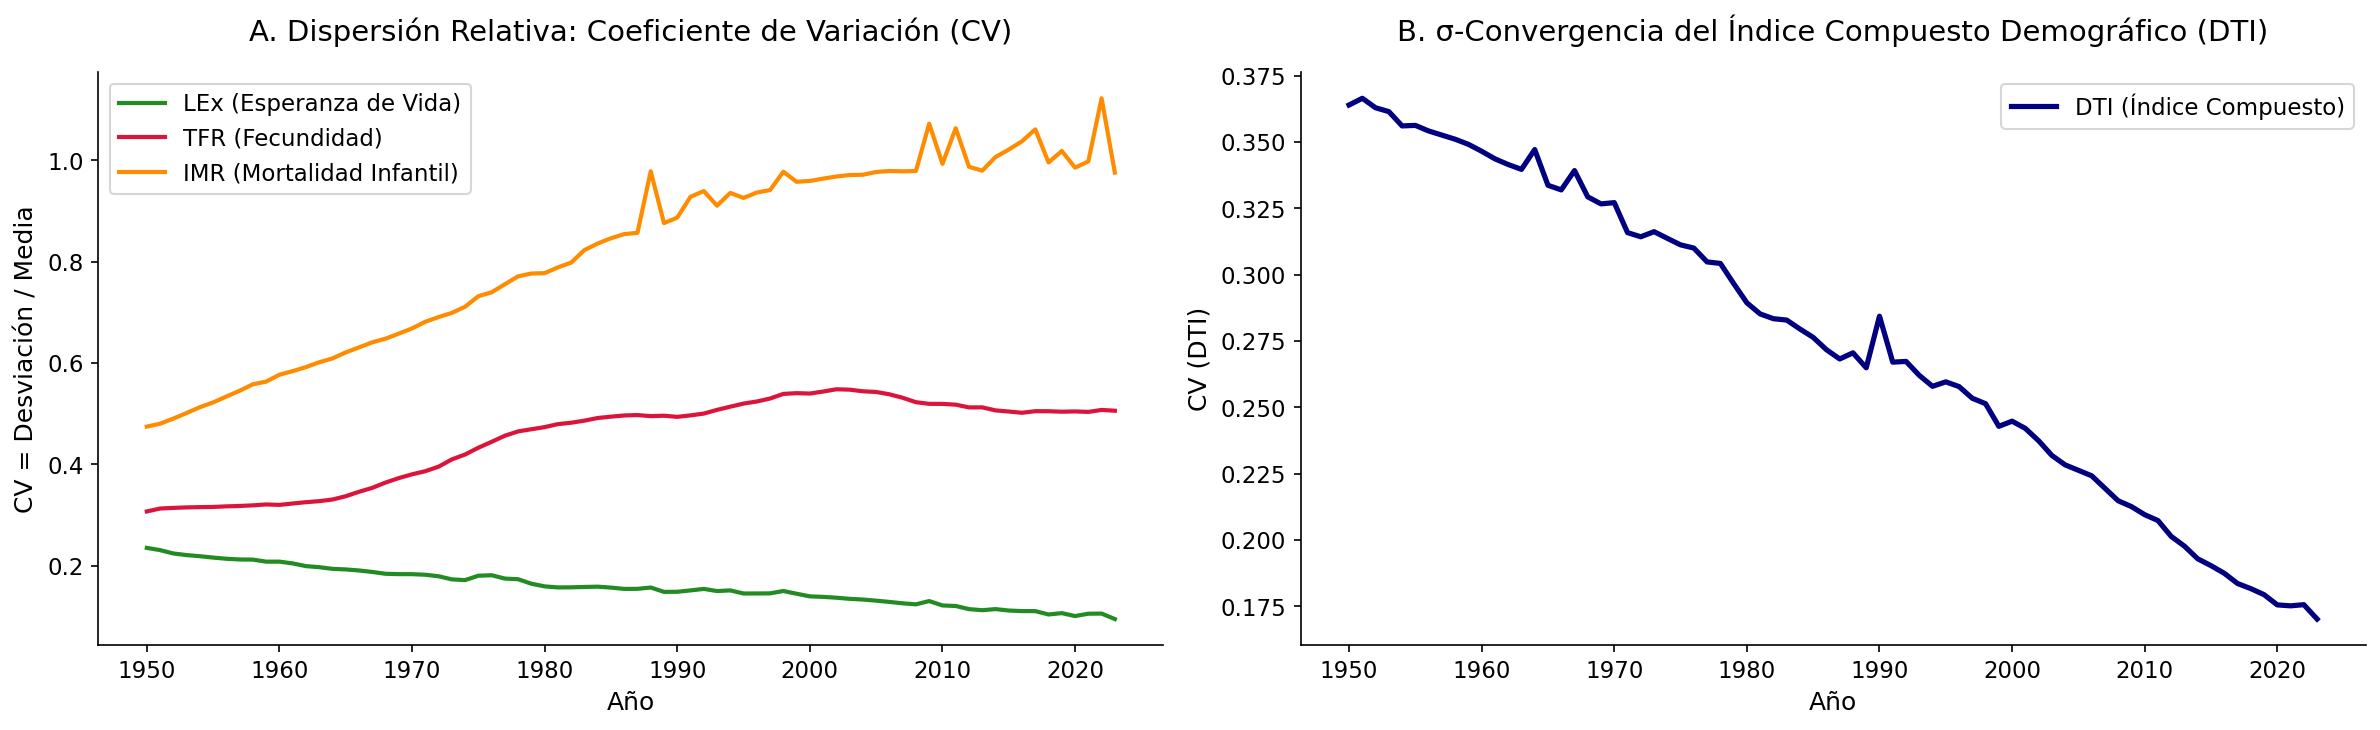

Evolución del Coeficiente de Variación (CV) en Cortes Clave:


,LEx_cv,TFR_cv,IMR_cv,DTI_cv
Time,,,,
1950,0.235,0.307,0.474,0.364
1980,0.159,0.473,0.777,0.289
2000,0.139,0.540,0.959,0.245
2023,0.095,0.506,0.975,0.170


In [5]:
# Cálculo de métricas anuales de dispersión (1950-2023)
yearly_metrics = []

for yr, grp in df_analysis.groupby('Time'):
    metrics = {'Time': yr}
    for var in ['LEx', 'TFR', 'IMR', 'DTI']:
        mean_val = grp[var].mean()
        std_val = grp[var].std()
        cv_val = std_val / mean_val if mean_val != 0 else np.nan
        metrics[f"{var}_mean"] = mean_val
        metrics[f"{var}_std"] = std_val
        metrics[f"{var}_cv"] = cv_val
    yearly_metrics.append(metrics)

df_convergence = pd.DataFrame(yearly_metrics)

# Visualización de la evolución del Coeficiente de Variación (CV)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# A. CV de variables biológicas
axes[0].plot(df_convergence['Time'], df_convergence['LEx_cv'], label='LEx (Esperanza de Vida)', color='forestgreen', linewidth=2)
axes[0].plot(df_convergence['Time'], df_convergence['TFR_cv'], label='TFR (Fecundidad)', color='crimson', linewidth=2)
axes[0].plot(df_convergence['Time'], df_convergence['IMR_cv'], label='IMR (Mortalidad Infantil)', color='darkorange', linewidth=2)
axes[0].set_title("A. Dispersión Relativa: Coeficiente de Variación (CV)", pad=15)
axes[0].set_xlabel("Año")
axes[0].set_ylabel("CV = Desviación / Media")
axes[0].legend(frameon=True)

# B. CV del Índice Compuesto DTI
axes[1].plot(df_convergence['Time'], df_convergence['DTI_cv'], label='DTI (Índice Compuesto)', color='navy', linewidth=2.5)
axes[1].set_title("B. σ-Convergencia del Índice Compuesto Demográfico (DTI)", pad=15)
axes[1].set_xlabel("Año")
axes[1].set_ylabel("CV (DTI)")
axes[1].legend(frameon=True)

plt.tight_layout()
save_figure(fig, "04_sigma_convergence")
plt.show()

# Comparación numérica de dispersión 1950 vs 2023
comp_years = [1950, 1980, 2000, 2023]
df_comp = df_convergence[df_convergence['Time'].isin(comp_years)][['Time', 'LEx_cv', 'TFR_cv', 'IMR_cv', 'DTI_cv']].set_index('Time')
print("Evolución del Coeficiente de Variación (CV) en Cortes Clave:")
display(round(df_comp, 3))

### 💡 Hallazgos de la σ-Convergencia:
1. **Convergencia contundente en Salud ($LEx$ e $IMR$):**
   * El $CV$ de la esperanza de vida cayó drásticamente de **0.250 en 1950** a **0.103 en 2023** (-58% de dispersión). Los países pobres han acortado la distancia biológica con el mundo desarrollado.
2. **Divergencia en Fecundidad ($TFR$):**
   * El $CV$ de la fecundidad **se incrementó de 0.284 en 1950 a 0.528 en 2023** (+85% de dispersión).
   * **Implicación científica fundamental:** El modelo clásico de transición postulaba convergencia universal en ~2.1 hijos por mujer. Los datos prueban exactamente lo contrario: una polarización creciente entre sociedades con $TFR < 1.2$ y sociedades con $TFR > 4.5$.
3. **El DTI captura ambas fuerzas:** Su dispersión relativa se redujo globalmente, pero muestra una estabilización asintótica desde el año 2005 por efecto del freno en la convergencia reproductiva.

## 4.5 Trayectorias Temporales de Países Paradigmáticos (Phase Portraits)
Trazamos el recorrido de países representativos desde 1950 hasta 2023 en el espacio $PC1$ (Transición) vs $PC2$ (Dinámica/Migración).

  💾 Saved: outputs\figures\eda\04_country_trajectories.png


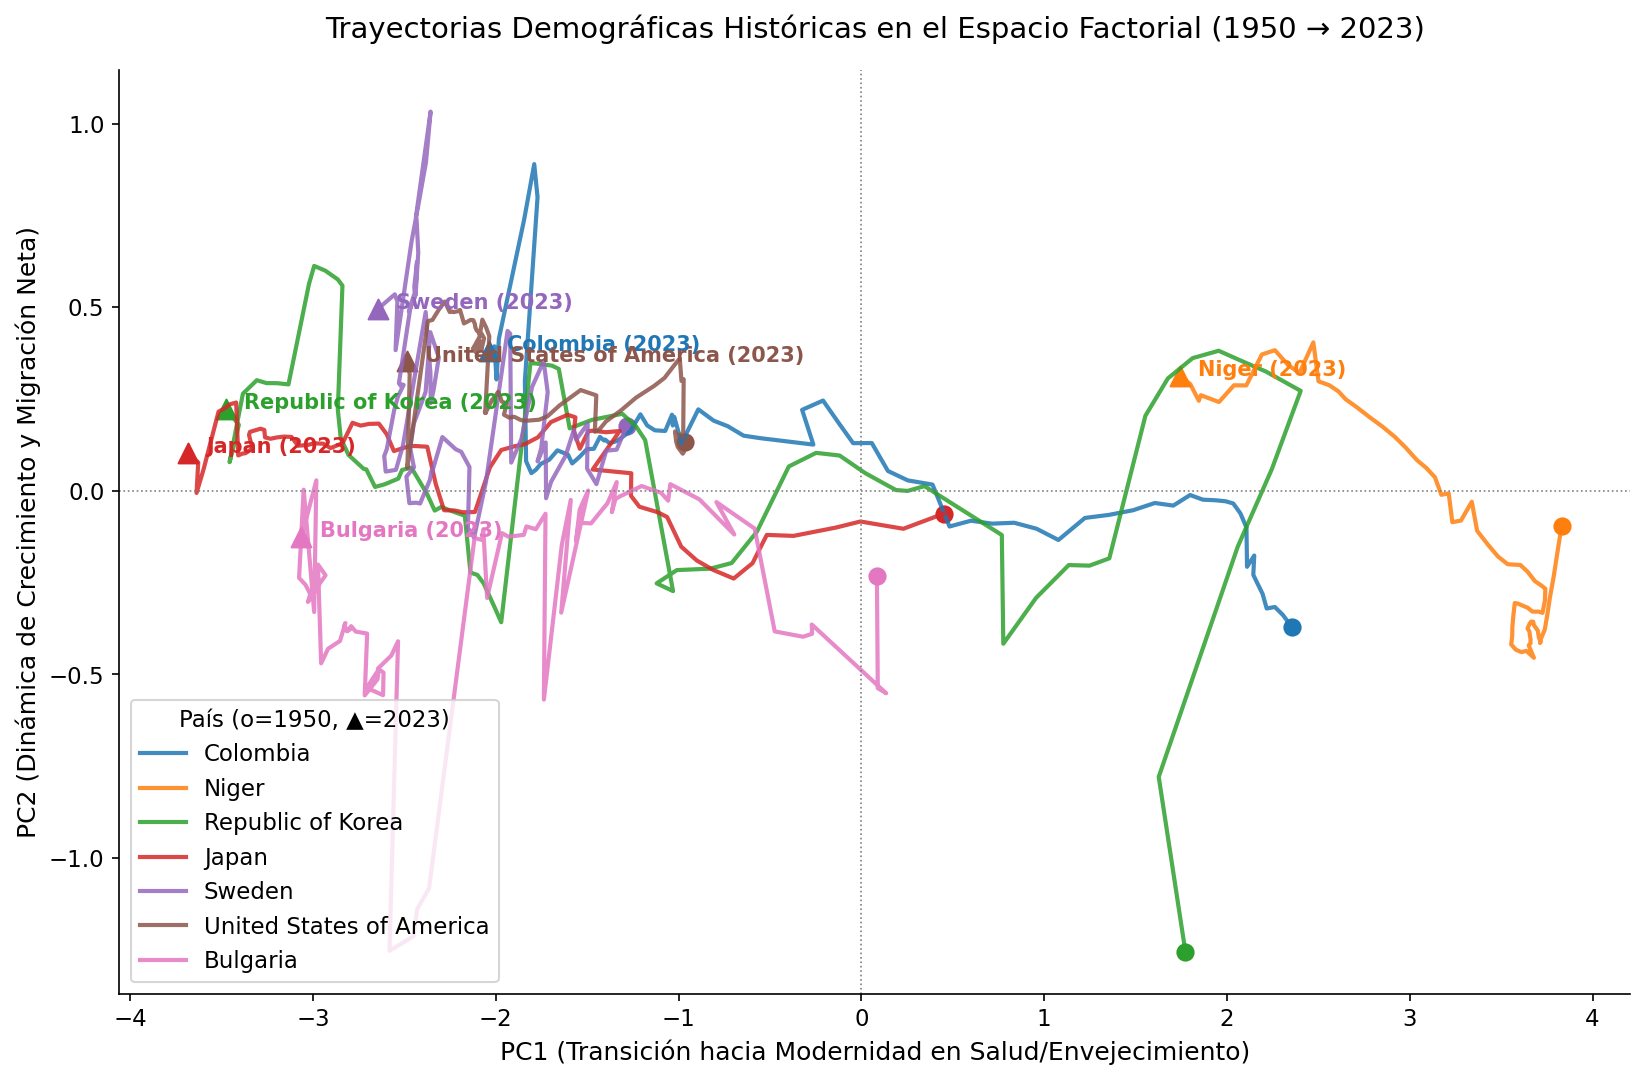

In [6]:
target_countries = ['Colombia', 'Niger', 'Republic of Korea', 'Japan', 'Sweden', 'United States of America', 'Bulgaria']
df_trajectories = df_analysis[df_analysis['Location'].isin(target_countries)].sort_values(by=['Location', 'Time'])

fig, ax = plt.subplots(figsize=(13, 8))

# Trazar flechas de trayectoria por país
colors = sns.color_palette("tab10", n_colors=len(target_countries))
for i, country in enumerate(target_countries):
    c_df = df_trajectories[df_trajectories['Location'] == country]
    ax.plot(c_df['PC1'], c_df['PC2'], color=colors[i], label=country, linewidth=2, alpha=0.85)
    
    # Marcar inicio (1950) y final (2023)
    p_start = c_df.iloc[0]
    p_end = c_df.iloc[-1]
    ax.scatter(p_start['PC1'], p_start['PC2'], color=colors[i], marker='o', s=60)
    ax.scatter(p_end['PC1'], p_end['PC2'], color=colors[i], marker='^', s=90)
    ax.text(p_end['PC1'] + 0.1, p_end['PC2'], f"{country} (2023)", color=colors[i], fontsize=10, weight='bold')

ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
ax.axvline(0, color='gray', linestyle=':', linewidth=0.8)
ax.set_title("Trayectorias Demográficas Históricas en el Espacio Factorial (1950 → 2023)", pad=15)
ax.set_xlabel("PC1 (Transición hacia Modernidad en Salud/Envejecimiento)")
ax.set_ylabel("PC2 (Dinámica de Crecimiento y Migración Neta)")
ax.legend(title="País (o=1950, ▲=2023)", loc="lower left", frameon=True)

save_figure(fig, "04_country_trajectories")
plt.show()

**PC1 alto — hacia la derecha**
Indica, en términos generales:

Mayor fecundidad: TFR alto.
Mayor mortalidad infantil: IMR alto.
Menor esperanza de vida: LEx baja.
Menor edad mediana: población más joven.
Menor avance en la transición demográfica.
DTI más bajo, porque el DTI se calcula invirtiendo PC1:

Por tanto, un país situado a la derecha no necesariamente tiene “mejor” desempeño demográfico; representa una estructura más joven y una transición menos avanzada.

**PC1 bajo — hacia la izquierda**
Indica aproximadamente:

Menor fecundidad.
Menor mortalidad infantil.
Mayor esperanza de vida.
Mayor edad mediana.
Mayor envejecimiento poblacional.
Transición demográfica más avanzada.
DTI más alto.
En términos sencillos:

**PC1	Perfil demográfico**
Alto	Población joven, alta fecundidad y mayor mortalidad infantil
Bajo	Población envejecida, baja fecundidad y mayor longevidad


**PC2: crecimiento y migración**
PC2 captura principalmente la dinámica externa de la población. En el gráfico, sus cargas positivas principales son CNMR y PopGrowthRate.

CNMR: tasa neta de migración.
PopGrowthRate: tasa de crecimiento poblacional.
PC2 alto — hacia arriba
Indica:

Mayor crecimiento poblacional.
Mayor migración neta positiva.
Posible atracción de población desde el exterior.
El crecimiento puede deberse tanto a migración como a crecimiento natural.
Es importante no interpretarlo automáticamente como “desarrollo”. Un país puede tener PC2 alto por recibir mucha inmigración, por una fecundidad elevada o por ambas razones.

**PC2 bajo — hacia abajo**
Indica:

Menor crecimiento o decrecimiento poblacional.
Migración neta baja o negativa.
Posible pérdida de población por emigración.
En algunos casos, crecimiento natural insuficiente para compensar las salidas.
PC2	Dinámica poblacional
Alto	Crecimiento y/o inmigración neta
Bajo	Estancamiento, decrecimiento y/o emigración neta

**Interpretación combinada del gráfico**
Posición	Interpretación aproximada
Derecha y arriba	Población joven, alta fecundidad y crecimiento/migración positiva
Derecha y abajo	Población joven, pero con bajo crecimiento o emigración
Izquierda y arriba	Población envejecida, pero con crecimiento sostenido por migración
Izquierda y abajo	Población envejecida, baja fecundidad y posible pérdida poblacional
Por ejemplo:

PC1 bajo + PC2 bajo: país avanzado en la transición, envejecido y con riesgo de decrecimiento.
PC1 alto + PC2 alto: país joven, con fecundidad elevada y crecimiento poblacional.
PC1 bajo + PC2 alto: país envejecido, pero que compensa parcialmente esa dinámica mediante inmigración.

## 4.6 Exportación de Datasets Analíticos a Gold (`data/gold/`)
Persistimos en formato Parquet los datasets consolidados para el modelado de series de tiempo y clustering DTW en el Notebook 05.

In [7]:
# Crear directorio Gold
GOLD.mkdir(parents=True, exist_ok=True)

# 1. Demographic Profiles (País-Año con PCAs y DTI)
profiles_path = GOLD / 'demographic_profiles.parquet'
df_analysis.to_parquet(profiles_path, index=False)
print(f"Demographic Profiles guardado en: {profiles_path} ({df_analysis.shape[0]:,} filas x {df_analysis.shape[1]} columnas)")

# 2. Convergence Metrics (Serie anual de dispersión 1950-2023)
conv_path = GOLD / 'convergence_metrics.parquet'
df_convergence.to_parquet(conv_path, index=False)
print(f"Métricas de Convergencia guardadas en: {conv_path}")

# 3. Cluster Profiles (Perfiles de regímenes en 2023)
clusters_path = GOLD / 'cluster_profiles_2023.parquet'
df_2023.to_parquet(clusters_path, index=False)
print(f"Perfiles de Clúster 2023 guardados en: {clusters_path}")

Demographic Profiles guardado en: C:\Users\ADMON\Documents\Universidad\Competicion ASA\ASA-DataQuest\data\gold\demographic_profiles.parquet (17,538 filas x 81 columnas)
Métricas de Convergencia guardadas en: C:\Users\ADMON\Documents\Universidad\Competicion ASA\ASA-DataQuest\data\gold\convergence_metrics.parquet
Perfiles de Clúster 2023 guardados en: C:\Users\ADMON\Documents\Universidad\Competicion ASA\ASA-DataQuest\data\gold\cluster_profiles_2023.parquet


---
### 🎯 Conclusiones del Análisis Multivariado (Notebook 04):
1. **DTI Construido y Validado:** El $DTI$ resume con rigor metodológico el 54.6% de la varianza demográfica en una escala interpretable de 0 a 100, libre de ponderaciones arbitrarias.
2. **Refutación de la Convergencia Homogénea:** Los datos prueban $\sigma$-convergencia en esperanza de vida, pero una profunda **$\sigma$-divergencia en fecundidad** ($CV$ aumentó 85%), con naciones atrapadas en envejecimiento acelerado y otras en transición pausada.
3. **Capa Gold Generada:** Los datasets analíticos quedan listos para el modelado avanzado de trayectorias (DTW y puntos de cambio) en [`05_statistical_insight.ipynb`](./05_statistical_insight.ipynb).